# 08 · Deep learning for demand forecasting: LSTM and Transformer vs Gradient Boosting

**Phase 5 · Deep learning.** Notebook 03 forecast the **orders in the next hour** with Gradient
Boosting on 11 hand-made features (calendar + lags 1 h, 2 h, 24 h, 168 h + 24-hour mean):
test MAE **8.51 orders/hour**, vs 10.34 for "same hour last week".

> Can a network that reads the **raw history** (the last 168 hours) forecast better?

| Model | Input |
|---|---|
| **Gradient Boosting v1** (Phase 3, reloaded) | 11 hand-made features |
| **MLP** | the same 11 features (neural network vs trees, identical input) |
| **LSTM** | the last 168 hours one by one (orders, hour, weekend, promotion) + calendar of the hour to forecast |
| **Transformer** | the same 168 hours as 14 blocks of 12 hours (PatchTST style), with **self-attention**: each part of the week can look directly at any other part |

**Small data warning.** 91 days = 2,184 hours; after the first week (needed as history) the training
split has **1,344 hours**. Deep networks usually need far more examples, so this is a real test of
whether they are worth it here. Because results of small networks depend on the random start, every
network is trained with **5 seeds**; we report mean ± standard deviation and the 5-seed ensemble.

Same split as notebook 03: train 7 Sep - 8 Nov, validation 9-22 Nov, test 23 Nov - 6 Dec
(includes Black Friday and Cyber Monday). Choices are made on validation; test is used once.

In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT))
from ai.deep_learning.demand import (  # noqa: E402
    HISTORY,
    STEP_FEATURES,
    TARGET_FEATURES,
    DemandLSTM,
    DemandMLP,
    DemandTransformer,
    calendar,
    history_windows,
    n_parameters,
    predict,
    train_regressor,
)  # fmt: skip

DATA = ROOT / "data" / "processed" / "classical_ml"
MODELS = ROOT / "models"
torch.set_num_threads(4)
print("torch", torch.__version__)

torch 2.14.1+cpu


## 1. Data: the same hours and features as notebook 03

In [2]:
df = calendar(pd.read_parquet(DATA / "demand_hourly.parquet").sort_values("timestamp").reset_index(drop=True))
assert (df["timestamp"].diff().dropna() == pd.Timedelta("1h")).all(), "timeline must be continuous"
TARGET = "orders_total"
FEATURES = [
    "hour_sin", "hour_cos", "day_of_week", "is_weekend", "month", "is_promo_day",
    "lag_1h_orders", "lag_2h_orders", "lag_24h_orders", "lag_168h_orders", "rolling_24h_mean_orders",
]  # fmt: skip
df["orders"] = df[TARGET].astype(float)
usable = df.dropna(subset=FEATURES).index.to_numpy()  # notebook 03's rows (full week of history)
rows = {s: usable[df.loc[usable, "split"].to_numpy() == s] for s in ("train", "validation", "test")}
y = {s: df.loc[r, TARGET].to_numpy(float) for s, r in rows.items()}
for s, r in rows.items():
    print(f"{s:10s} {len(r):5,} hours  {df.loc[r[0], 'timestamp']} .. {df.loc[r[-1], 'timestamp']}")

train      1,344 hours  2026-09-14 00:00:00 .. 2026-11-08 23:00:00
validation   336 hours  2026-11-09 00:00:00 .. 2026-11-22 23:00:00
test         336 hours  2026-11-23 00:00:00 .. 2026-12-06 23:00:00


## 2. Reference models

The Phase 3 model is reloaded (not retrained) and must reproduce its test MAE of 8.51.

In [3]:
def mae(y_true, y_pred):
    return round(float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))), 2)


gb = joblib.load(MODELS / "demand_v1.joblib")
pred_val, pred_test, summary = {}, {}, {}
pred_val["Same hour last week"] = df.loc[rows["validation"], "lag_168h_orders"].to_numpy()
pred_test["Same hour last week"] = df.loc[rows["test"], "lag_168h_orders"].to_numpy()
pred_val["Gradient Boosting v1"] = gb.predict(df.loc[rows["validation"], FEATURES])
pred_test["Gradient Boosting v1"] = gb.predict(df.loc[rows["test"], FEATURES])
for name in pred_test:
    summary[name] = {"val_MAE": mae(y["validation"], pred_val[name]), "test_MAE": mae(y["test"], pred_test[name]),
                     "test_MAE_std_over_seeds": None, "parameters": None}  # fmt: skip
pd.DataFrame(summary).T

,val_MAE,test_MAE,test_MAE_std_over_seeds,parameters
Same hour last week,9.9,10.34,NaN,NaN
Gradient Boosting v1,8.7,8.51,NaN,NaN


## 3. Inputs for the networks

* **MLP:** the 11 features, standardised on train.
* **LSTM / Transformer:** for each hour to forecast, the 168 hours before it, each described by
  orders, hour_sin, hour_cos, is_weekend, is_promo_day (orders standardised on train),
  plus the calendar of the hour to forecast (hour, weekday, weekend, promotion; known in advance).

The target is standardised too (mean 0, std 1 on train) and converted back for the MAE.

In [4]:
y_scale = (float(y["train"].mean()), float(y["train"].std()))
f_mean = df.loc[rows["train"], FEATURES].mean()
f_std = df.loc[rows["train"], FEATURES].std().replace(0, 1)
tab = {s: (((df.loc[r, FEATURES] - f_mean) / f_std).to_numpy(np.float32),) for s, r in rows.items()}
seq = {s: history_windows(df, r, y_scale) for s, r in rows.items()}
print("MLP input:", tab["train"][0].shape, "| sequence input:", seq["train"][0].shape, "+ target calendar", seq["train"][1].shape)

MLP input: (1344, 11) | sequence input: (1344, 168, 5) + target calendar (1344, 6)


## 4. Train every network with 5 seeds

Loss = mean absolute error (the metric we report), AdamW, early stopping on validation MAE (the best
epoch is kept). Each seed changes the random initial weights and the order of training examples.

Every finished run (weights, history, forecasts) is saved in `data/processed/deep_learning/demand_runs/`;
re-running the notebook reuses finished runs, so an interruption never loses work. Delete that folder
to retrain from scratch.

| Network | Batch | Max epochs | Patience | Time per epoch (laptop CPU) |
|---|---|---|---|---|
| MLP | 64 | 250 | 25 | < 1 s |
| LSTM (168 hourly steps) | 128 | 150 | 20 | ~ 3-4 s |
| Transformer (14 patches) | 64 | 250 | 25 | ~ 1 s |

In [5]:
SEEDS = [42, 43, 44, 45, 46]
RUNS = ROOT / "data" / "processed" / "deep_learning" / "demand_runs"
RUNS.mkdir(parents=True, exist_ok=True)
families = {
    "MLP": (lambda: DemandMLP(len(FEATURES)), tab, {"epochs": 250, "batch": 64, "patience": 25}),
    "LSTM": (lambda: DemandLSTM(len(STEP_FEATURES), len(TARGET_FEATURES), hidden=32), seq,
             {"epochs": 150, "batch": 128, "patience": 20}),
    "Transformer": (lambda: DemandTransformer(len(STEP_FEATURES), len(TARGET_FEATURES)), seq,
                    {"epochs": 250, "batch": 64, "patience": 25}),
}  # fmt: skip
runs, histories, models = [], {}, {}
for family, (make, data, settings) in families.items():
    for seed in SEEDS:
        torch.manual_seed(seed)
        model = make()
        cache = RUNS / f"{family}_{seed}.pt"
        if cache.exists():
            saved = torch.load(cache, weights_only=False)
            model.load_state_dict(saved["state_dict"])
            hist, seconds, note = pd.DataFrame(saved["history"]), saved["seconds"], "(saved run)"
        else:
            start = time.time()
            hist = train_regressor(model, data["train"], y["train"], data["validation"], y["validation"],
                                   y_scale, lr=1e-3, seed=seed, **settings)  # fmt: skip
            seconds, note = round(time.time() - start), ""
            torch.save({"state_dict": model.state_dict(), "history": hist.to_dict("records"),
                        "seconds": seconds}, cache)  # fmt: skip
        p_val, p_test = predict(model, data["validation"], y_scale), predict(model, data["test"], y_scale)
        runs.append({"model": family, "seed": seed, "epochs": len(hist), "seconds": seconds,
                     "val_MAE": mae(y["validation"], p_val), "test_MAE": mae(y["test"], p_test),
                     "parameters": n_parameters(model), "p_val": p_val, "p_test": p_test})  # fmt: skip
        histories[(family, seed)], models[(family, seed)] = hist, model
        print(f"{family:11s} seed {seed}: {len(hist):3d} epochs, {seconds:5d} s, "
              f"val MAE {runs[-1]['val_MAE']:.2f} {note}")  # fmt: skip
runs = pd.DataFrame(runs)

MLP         seed 42: 131 epochs,    13 s, val MAE 7.84 (saved run)
MLP         seed 43:  76 epochs,     7 s, val MAE 7.78 (saved run)
MLP         seed 44:  60 epochs,     5 s, val MAE 7.93 (saved run)
MLP         seed 45:  58 epochs,     5 s, val MAE 7.85 (saved run)
MLP         seed 46: 118 epochs,    11 s, val MAE 7.87 (saved run)


LSTM        seed 42: 105 epochs,   125 s, val MAE 7.77 (saved run)
LSTM        seed 43: 120 epochs,   102 s, val MAE 7.86 (saved run)
LSTM        seed 44: 105 epochs,    67 s, val MAE 7.78 (saved run)
LSTM        seed 45: 150 epochs,    95 s, val MAE 7.74 (saved run)


LSTM        seed 46: 108 epochs,    56 s, val MAE 7.88 (saved run)
Transformer seed 42:  42 epochs,    37 s, val MAE 7.80 (saved run)
Transformer seed 43:  53 epochs,    34 s, val MAE 7.96 (saved run)
Transformer seed 44:  91 epochs,    57 s, val MAE 7.46 (saved run)


Transformer seed 45:  82 epochs,    51 s, val MAE 7.67 (saved run)
Transformer seed 46:  59 epochs,    59 s, val MAE 7.53 (saved run)


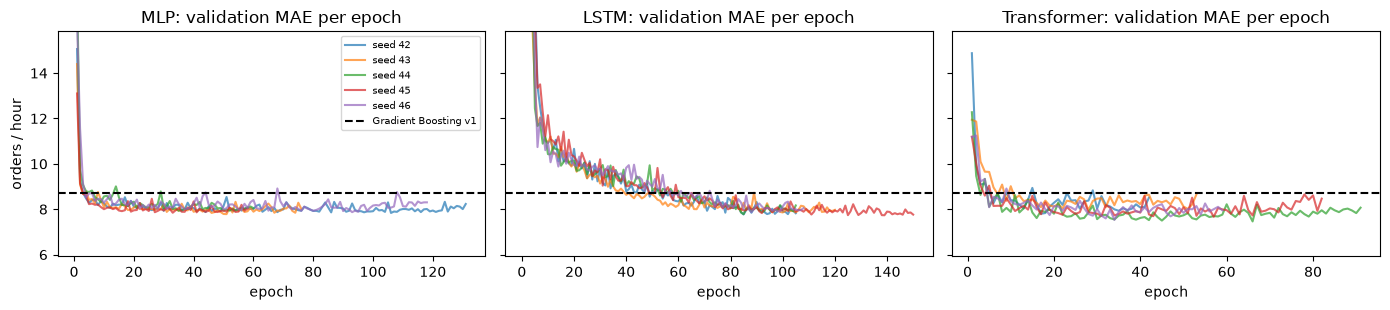

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, family in zip(axes, families, strict=False):
    for seed in SEEDS:
        h = histories[(family, seed)]
        ax.plot(h["epoch"], h["val_mae"], alpha=0.7, label=f"seed {seed}")
    ax.axhline(summary["Gradient Boosting v1"]["val_MAE"], color="k", ls="--", label="Gradient Boosting v1")
    ax.set_title(f"{family}: validation MAE per epoch")
    ax.set_xlabel("epoch")
axes[0].set_ylabel("orders / hour")
axes[0].legend(fontsize=7)
axes[0].set_ylim(top=summary["Same hour last week"]["val_MAE"] * 1.6)
plt.tight_layout()
plt.show()

## 5. Test results

For each network: mean ± standard deviation of the 5 seeds' test MAE, and the **5-seed ensemble**
(the average of the 5 forecasts, a standard way to make small networks more stable).

In [7]:
for family in families:
    part = runs[runs["model"] == family]
    summary[family + " (mean of 5 seeds)"] = {
        "val_MAE": round(part["val_MAE"].mean(), 2), "test_MAE": round(part["test_MAE"].mean(), 2),
        "test_MAE_std_over_seeds": round(part["test_MAE"].std(), 2), "parameters": int(part["parameters"].iloc[0]),
    }  # fmt: skip
    pred_val[family + " ensemble"] = np.mean(np.stack(part["p_val"].to_list()), axis=0)
    pred_test[family + " ensemble"] = np.mean(np.stack(part["p_test"].to_list()), axis=0)
    summary[family + " ensemble"] = {"val_MAE": mae(y["validation"], pred_val[family + " ensemble"]),
                                     "test_MAE": mae(y["test"], pred_test[family + " ensemble"]),
                                     "test_MAE_std_over_seeds": None,
                                     "parameters": 5 * int(part["parameters"].iloc[0])}  # fmt: skip
table = pd.DataFrame(summary).T
base = summary["Gradient Boosting v1"]["test_MAE"]
table["vs Gradient Boosting v1"] = [f"{(v / base - 1) * 100:+.1f} %" for v in table["test_MAE"]]
table

,val_MAE,test_MAE,test_MAE_std_over_seeds,parameters,vs Gradient Boosting v1
Same hour last week,9.90,10.34,NaN,NaN,+21.5 %
Gradient Boosting v1,8.70,8.51,NaN,NaN,+0.0 %
MLP (mean of 5 seeds),7.85,7.74,0.22,4993.0,-9.0 %
MLP ensemble,7.71,7.42,NaN,24965.0,-12.8 %
LSTM (mean of 5 seeds),7.81,7.82,0.18,6273.0,-8.1 %
LSTM ensemble,7.68,7.61,NaN,31365.0,-10.6 %
Transformer (mean of 5 seeds),7.68,7.83,0.36,21793.0,-8.0 %
Transformer ensemble,7.47,7.44,NaN,108965.0,-12.6 %


**Where are the errors?** Test MAE by situation: normal hours vs promotion days (Black Friday,
Cyber Monday) and the busiest 10 % of hours.

In [8]:
test_rows = df.loc[rows["test"]].reset_index(drop=True)
busy = test_rows[TARGET] >= test_rows[TARGET].quantile(0.9)
groups = {"all hours": np.ones(len(test_rows), bool), "normal days": ~test_rows["is_promo_day"].astype(bool).to_numpy(),
          "promotion days": test_rows["is_promo_day"].astype(bool).to_numpy(), "busiest 10 % of hours": busy.to_numpy()}  # fmt: skip
show = ["Same hour last week", "Gradient Boosting v1", "MLP ensemble", "LSTM ensemble", "Transformer ensemble"]
by_situation = pd.DataFrame({g: {m: mae(y["test"][mask], pred_test[m][mask]) for m in show} for g, mask in groups.items()})
by_situation["hours"] = None
by_situation.loc["(number of hours)"] = {g: int(mask.sum()) for g, mask in groups.items()}
by_situation.drop(columns="hours")

,all hours,normal days,promotion days,busiest 10 % of hours
Same hour last week,10.34,9.71,14.12,18.26
Gradient Boosting v1,8.51,7.87,12.33,20.31
MLP ensemble,7.42,7.08,9.47,14.38
LSTM ensemble,7.61,7.29,9.53,15.55
Transformer ensemble,7.44,7.06,9.76,16.77
(number of hours),336.00,288.00,48.00,34.00


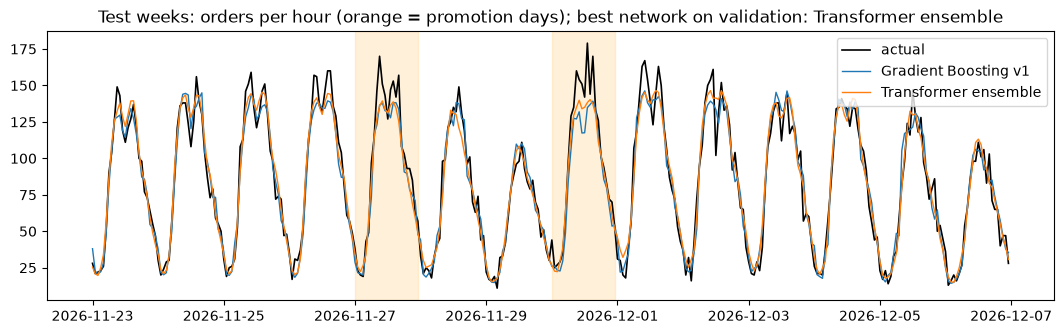

In [9]:
best_dl = min([f + " ensemble" for f in families], key=lambda n: summary[n]["val_MAE"])
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(test_rows["timestamp"], y["test"], color="k", lw=1.2, label="actual")
ax.plot(test_rows["timestamp"], pred_test["Gradient Boosting v1"], lw=1, label="Gradient Boosting v1")
ax.plot(test_rows["timestamp"], pred_test[best_dl], lw=1, label=best_dl)
for _, day in test_rows[test_rows["is_promo_day"].astype(bool)].groupby("date"):
    ax.axvspan(day["timestamp"].iloc[0], day["timestamp"].iloc[-1], color="orange", alpha=0.15)
ax.set_title(f"Test weeks: orders per hour (orange = promotion days); best network on validation: {best_dl}")
ax.legend()
plt.show()

## 6. Why do the networks win? Two control checks

1. **Is it the loss?** The networks minimise absolute error; Gradient Boosting v1 minimised squared
   error. Control: the same Gradient Boosting trained on absolute error.
2. **Is it extrapolation?** A tree model forecasts averages of training values, so it can never
   forecast above the busiest hours it has seen. Control: linear regression (which can extrapolate)
   on the same features. We also compare the highest forecast with the highest actual value.

In [10]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X = {s: df.loc[r, FEATURES] for s, r in rows.items()}
controls = {
    "Gradient Boosting, absolute loss": HistGradientBoostingRegressor(
        loss="absolute_error", learning_rate=0.03, min_samples_leaf=30, max_iter=300, random_state=42),
    "Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
}  # fmt: skip
for name, model in controls.items():
    model.fit(X["train"], y["train"])
    pred_val[name], pred_test[name] = model.predict(X["validation"]), model.predict(X["test"])
busy_mask = groups["busiest 10 % of hours"]
why = pd.DataFrame({
    name: {"test MAE": mae(y["test"], pred_test[name]), "MAE busiest 10 % of hours": mae(y["test"][busy_mask], pred_test[name][busy_mask]),
           "highest forecast": round(float(pred_test[name].max()))}
    for name in ["Gradient Boosting v1", "Gradient Boosting, absolute loss", "Linear regression",
                 "MLP ensemble", "LSTM ensemble", "Transformer ensemble"]
}).T  # fmt: skip
print(f"highest actual orders/hour: train {y['train'].max():.0f}, test {y['test'].max():.0f}; "
      f"test hours above the training maximum: {(y['test'] > y['train'].max()).sum()}")
why

highest actual orders/hour: train 164, test 179; test hours above the training maximum: 4


,test MAE,MAE busiest 10 % of hours,highest forecast
Gradient Boosting v1,8.51,20.31,146.0
"Gradient Boosting, absolute loss",8.49,20.49,143.0
Linear regression,8.38,14.72,160.0
MLP ensemble,7.42,14.38,157.0
LSTM ensemble,7.61,15.55,153.0
Transformer ensemble,7.44,16.77,147.0


**Consistency per day:** mean absolute error per test day (14 days) for Gradient Boosting v1 and
the network chosen on validation.

In [11]:
day = test_rows["date"].astype(str).to_numpy()
per_day = pd.DataFrame({m: {d: mae(y["test"][day == d], pred_test[m][day == d]) for d in np.unique(day)}
                        for m in ["Gradient Boosting v1", best_dl]})  # fmt: skip
per_day["promotion"] = test_rows.groupby("date")["promo_name"].first().fillna("").astype(str).to_numpy()
better_days = int((per_day[best_dl] < per_day["Gradient Boosting v1"]).sum())
print(f"{best_dl} has a lower error on {better_days} of {len(per_day)} test days")
per_day

Transformer ensemble has a lower error on 10 of 14 test days


,Gradient Boosting v1,Transformer ensemble,promotion
2026-11-23,5.54,5.54,
2026-11-24,7.95,6.01,
2026-11-25,7.71,7.01,
2026-11-26,8.91,7.16,
2026-11-27,10.83,9.98,Black Friday
2026-11-28,7.97,8.47,
2026-11-29,5.23,4.43,
2026-11-30,13.83,9.53,Cyber Monday
2026-12-01,9.75,9.97,
2026-12-02,10.13,8.58,


## 7. Save

The best network family on **validation** is saved (its best-validation seed) with its scaling, plus
the full comparison report. Gradient Boosting v1 stays the live demand model unless a network beats it
clearly on test.

In [12]:
family = best_dl.replace(" ensemble", "")
best_run = runs[runs["model"] == family].sort_values("val_MAE").iloc[0]
model = models[(family, int(best_run["seed"]))]
torch.save({"arch": family, "state_dict": model.state_dict(), "history": HISTORY,
            "step_features": STEP_FEATURES, "target_features": TARGET_FEATURES, "features": FEATURES,
            "y_scale": y_scale, "feature_mean": f_mean.tolist(), "feature_std": f_std.tolist()},
           MODELS / "demand_dl_v1.pt")  # fmt: skip
report = {
    "model": "demand_dl_v1",
    "dataset_version": "v3",
    "question": "Do neural networks (MLP, LSTM, Transformer) forecast hourly orders better than Gradient Boosting?",
    "split_hours": {s: len(r) for s, r in rows.items()},
    "history_hours": HISTORY,
    "seeds": SEEDS,
    "summary": summary,
    "runs": runs.drop(columns=["p_val", "p_test"]).to_dict("records"),
    "test_mae_by_situation": by_situation.drop(columns="hours").to_dict(),
    "best_network_on_validation": best_dl,
    "why_networks_win": why.to_dict("index"),
    "days_better_than_gradient_boosting": {"days": better_days, "of": len(per_day)},
    "saved_seed": int(best_run["seed"]),
}
(MODELS / "demand_dl_v1_report.json").write_text(json.dumps(report, indent=2, default=float))
print("Saved models/demand_dl_v1.pt and models/demand_dl_v1_report.json")

Saved models/demand_dl_v1.pt and models/demand_dl_v1_report.json

## 8. Conclusions

**Test MAE, orders per hour (lower is better; test = 23 Nov - 6 Dec, 336 hours):**

| Model | Test MAE | vs Gradient Boosting v1 | Busiest 10 % of hours |
|---|---|---|---|
| Same hour last week | 10.34 | +21.5 % | 18.26 |
| Gradient Boosting v1 (Phase 3) | 8.51 | reference | 20.31 |
| Linear regression (control) | 8.38 | -1.5 % | 14.72 |
| MLP, 5-seed ensemble | **7.42** | **-12.8 %** | **14.38** |
| LSTM, 5-seed ensemble | 7.61 | -10.6 % | 15.55 |
| Transformer (PatchTST-style), 5-seed ensemble | 7.44 | -12.6 % | 16.77 |

1. **All three networks beat Gradient Boosting by 10-13 %**, also as single models (mean of 5 seeds
   7.74 / 7.82 / 7.83, standard deviation 0.2-0.4). The network chosen on validation, the
   Transformer ensemble, is better on 10 of 14 test days (one tie), with its largest gains on the
   promotion days: Cyber Monday 13.8 -> 9.5, Black Friday 10.8 -> 10.0.
2. **Why: trees cannot forecast beyond what they have seen.** Gradient Boosting never forecast more
   than 146 orders/hour, but the test weeks reach 179 (above the training maximum of 164). In the
   busiest hours its error is 20 orders/hour. Training it on absolute error does not help (8.49), so
   the loss is not the reason. Networks, like linear regression, can extrapolate, and unlike linear
   regression they also capture non-linear patterns.
3. **The three networks are about equal.** The MLP on the same 11 features is as good as the sequence
   models: on hourly totals, the hand-made lags already hold most of the history. Differences between
   MLP, LSTM and Transformer are within seed-to-seed variation.
4. **Ensembles help:** averaging 5 seeds lowers the error by 0.2-0.4 compared with a single network,
   and removes the luck of one random start.

**Limits:** 1,344 training hours and a 2-week test set; the test weeks contain an unusual peak period
(Black Friday, Cyber Monday), which is exactly where the networks gain. On ordinary days the
difference is smaller and Gradient Boosting is sometimes better (3 of 14 days).

**Decision:** the saved network (`models/demand_dl_v1.pt`) is a candidate replacement for the live
demand model; Gradient Boosting v1 stays live until the integration step adds the network to the app.